# 11 — Choques na média, dispersão e forma com propagação condicional

> **Versão SPW=13.882494684620836.** Esta suíte usa um novo retreino com `scale_pos_weight=13.882494684620836` e limiar fixo `0,50`. O desenho do `model_final.ipynb` foi mantido, exceto pelo peso de classe solicitado. O modelo congelado e sua configuração estão em `models/`; os dados de entrada devem estar em `data/raw/`.


**Objetivo.** Aprender a construir uma mudança gradual em uma variável, medir o drift produzido e observar a reação do modelo quando outras entradas acompanham parcialmente a mudança. O exemplo usa `MonthlyIncome` e o mesmo *hold-out* do `model_final.ipynb`. São **180 cenários**: 3 famílias de choque × 2 direções × 10 intensidades (5%, 10%, …, 50%) × 3 graus de propagação (0, 0,5, 1). A grade inteira é executada sem critério de parada.

O modelo é o `model_class_retreinado.json` descrito no manifesto. Ele retreina com `scale_pos_weight=13.882494684620836` e mantém os demais parâmetros, mas não é o objeto da sessão original. `cs-test.csv` não tem rótulos. Aqui os valores são sintéticos; **não calculamos Brier, AUC ROC, PR-AUC trapezoidal ou KS do modelo com os rótulos históricos**, pois eles não são os desfechos contrafactuais após uma mudança real de renda e das demais características. Os números são sensibilidade de scores e decisões a uma hipótese de cenário. O conjunto não tem data para validação fora de tempo.

## O que cada choque significa

Com $x_i$ como renda mensal, $r\in\{-0{,}50,-0{,}45,\ldots,-0{,}05,+0{,}05,\ldots,+0{,}45,+0{,}50\}$, $m$ como mediana observada e $u_i$ como posto percentual:

| Família | Fórmula | Parâmetro `r` | Efeito principal esperado |
|---|---|---|---|
| Média (escala) | $x_i'=x_i(1+r)$ | de ±5% a ±50%, em passos de 5% no valor, para cada renda observada | Média e mediana mudam pelo mesmo percentual; o desvio padrão também muda. |
| Dispersão | $x_i'=\max(0,m+(x_i-m)(1+r))$ | de ±5% a ±50%, em passos de 5% na distância à mediana antes do piso zero | Desvio padrão muda; média pode mudar por assimetria e piso zero. |
| Cauda/forma | $x_i'=x_i\,[1+r\,\max(0,(u_i-0{,}75)/0{,}25)]$ | Até ±50% no topo da cauda, em passos de 5%; nada abaixo do percentil 75 | A cauda superior muda gradualmente; média e desvio padrão podem mudar. |

Portanto `+50% dispersão` **não** quer dizer +50% na média; reportamos a mudança realmente obtida em cada momento e quantil. Rendas ausentes continuam ausentes. `MonthlyIncome` tem cauda extrema e muitos ausentes, por isso também mostramos mediana, P95, P99, taxa de ausentes e fração que extrapola o suporte do *hold-out*.

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


## 1. Propagação pela dependência de postos

Transformamos as dez entradas em postos e depois em escores normais latentes:

$$u_{ij}=\frac{R_{ij}-0{,}5}{n},\qquad z_{ij}=\Phi^{-1}(u_{ij}).$$

Aqui $R_{ij}$ é o posto médio do registro $i$ na variável $j$, $n$ é o tamanho da referência, e $\Phi^{-1}$ é o quantil normal padrão. Empates recebem posto médio. Para estimar a estrutura de dependência, valores ausentes são preenchidos pela mediana **apenas no espaço latente**; as máscaras de ausentes são restauradas na base que chega ao modelo. Estimamos a matriz de correlação $\Sigma$ dos $z$.

Após transformar a renda $S$, calculamos seu novo escore latente $z'_S$ usando a **distribuição de referência**. Para cada outra variável $j$, usamos

$$z'_j=z_j+\lambda\,\frac{\Sigma_{jS}}{\Sigma_{SS}}\,(z'_S-z_S),\qquad x'_j=F_j^{-1}(\Phi(z'_j)).$$

$\lambda=0$ deixa as demais entradas fixas; $0{,}5$ aplica metade do deslocamento condicional; $1$ aplica todo o deslocamento da **média condicional latente** estimada. O resíduo latente $z_j-(\Sigma_{jS}/\Sigma_{SS})z_S$ fica constante quando $\lambda=1$, antes da discretização. A inversão empírica recoloca cada variável na sua escala observada e arredonda idade e contagens. **Isso é uma regra associativa de cenário, não uma afirmação causal de que renda causa mudança nas outras entradas.** Com empates, ausentes e caudas, a dependência observada pode não ser preservada exatamente; medimos a diferença de correlação de Spearman.

O mapeamento da renda usa a CDF empírica da referência. Se um cenário sai além do mínimo/máximo observado, a normalização latente precisa saturar na borda. Registramos essa fração como `fora_suporte_alvo`; não tratamos extrapolação como evidência calibrada.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from scipy.stats import norm, rankdata, wasserstein_distance
from sklearn.model_selection import train_test_split
from IPython.display import display

ROOT = DATA_DIR_PROJECT
if not (ROOT / 'cs-training.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'cs-training.csv').exists(), 'Inicie da raiz do projeto ou de notebooks//.'
OUT = TABLES_DIR
manifest = json.loads((MODEL_DIR / 'manifesto_modelo.json').read_text(encoding='utf-8'))
FEATURES = manifest['features']
TARGET = 'MonthlyIncome'
TARGET_IDX = FEATURES.index(TARGET)
CUTOFF = float(manifest['cutoff'])
INTEGER_FEATURES = {'age', 'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'}
model_class = xgb.Booster(model_file=str(MODEL_DIR / 'model_class_retreinado.json'))
model_class.set_param({'device':'cpu'})
assert model_class.feature_names == FEATURES
print('Modelo:', xgb.__version__, '| variável alvo do choque:', TARGET, '| corte:', CUTOFF)

Modelo: 3.0.0 | variável alvo do choque: MonthlyIncome | corte: 0.5


In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 2. Referência e diagnóstico inicial

Reproduzimos o split original sem estratificação. A correlação de Spearman mede associação monotônica entre postos; ela não mede causalidade. Como a renda tem valores extremos, os percentis são essenciais para entender seu comportamento além da média.

In [4]:
raw = pd.read_csv(ROOT / 'cs-training.csv').drop(columns=['Unnamed: 0'])
_, X_hold, _, y_hold = train_test_split(raw[FEATURES], raw[manifest['target']],
                                         test_size=0.15, random_state=33)
X_hold = X_hold.reset_index(drop=True)

def predict(frame):
    dm = xgb.DMatrix(frame[FEATURES], feature_names=FEATURES, enable_categorical=True)
    return model_class.predict(dm)

p_ref = predict(X_hold)
ref_corr = X_hold[FEATURES].corr(method='spearman')
ref_income = X_hold[TARGET].dropna().to_numpy(dtype=float)
display(pd.DataFrame({
    'n':[len(X_hold)], 'renda_ausente_pct':[100*X_hold[TARGET].isna().mean()],
    'media':[np.mean(ref_income)], 'desvio_padrao':[np.std(ref_income)],
    'mediana':[np.median(ref_income)], 'p95':[np.quantile(ref_income, .95)],
    'p99':[np.quantile(ref_income, .99)], 'max':[np.max(ref_income)]
}).round(2))
display(ref_corr[TARGET].drop(TARGET).sort_values(ascending=False).to_frame('Spearman com renda').round(3))

,n,renda_ausente_pct,media,desvio_padrao,mediana,p95,p99,max
0,22500,19.69,6627.57,8967.52,5333.0,14779.9,25000.0,629000.0


,Spearman com renda
NumberRealEstateLoansOrLines,0.396
NumberOfOpenCreditLinesAndLoans,0.318
NumberOfDependents,0.207
age,0.140
NumberOfTime30-59DaysPastDueNotWorse,-0.025
NumberOfTime60-89DaysPastDueNotWorse,-0.053
RevolvingUtilizationOfUnsecuredLines,-0.083
NumberOfTimes90DaysLate,-0.098
DebtRatio,-0.129


## 3. Ajuste da dependência latente e teste de choque zero

O ajuste usa somente a distribuição do *hold-out*, sem o rótulo. Para reaplicar em produção, a referência e seus quantis precisam ser congelados; não se deve recalcular a referência a cada janela. A regra aqui é uma demonstração com o conjunto disponível. Validamos que intensidade zero devolve **os mesmos dados e scores** antes de interpretar qualquer cenário.

In [5]:
n = len(X_hold)
missing_masks = {f: X_hold[f].isna().to_numpy() for f in FEATURES}
medians = {f: float(X_hold[f].median()) for f in FEATURES}
filled = X_hold[FEATURES].fillna(medians).astype(float)
A = filled.to_numpy()
sorted_ref = {f: np.sort(A[:, j]) for j, f in enumerate(FEATURES)}
ranks = rankdata(A, axis=0, method='average')
U = (ranks - 0.5) / n
Z = norm.ppf(U)
Sigma = np.corrcoef(Z, rowvar=False)
beta = Sigma[:, TARGET_IDX] / Sigma[TARGET_IDX, TARGET_IDX]
beta[TARGET_IDX] = 0.0
print('Coeficientes condicionais latentes relativos a MonthlyIncome:')
display(pd.Series(beta, index=FEATURES).drop(TARGET).sort_values(ascending=False).round(3).to_frame('beta_j'))

def normal_score_against_reference(values, sorted_values):
    v = np.asarray(values, dtype=float)
    left = np.searchsorted(sorted_values, v, side='left')
    right = np.searchsorted(sorted_values, v, side='right')
    u = (left + right) / (2 * len(sorted_values))
    u = np.clip(u, 0.5 / len(sorted_values), 1 - 0.5 / len(sorted_values))
    return norm.ppf(u)

def inverse_reference_quantile(z, sorted_values):
    u = np.clip(norm.cdf(z), 0.5 / len(sorted_values), 1 - 0.5 / len(sorted_values))
    grid = (np.arange(len(sorted_values)) + 0.5) / len(sorted_values)
    return np.interp(u, grid, sorted_values)

assert np.max(np.abs(normal_score_against_reference(A[:, TARGET_IDX], sorted_ref[TARGET])
                     - Z[:, TARGET_IDX])) < 1e-8

Coeficientes condicionais latentes relativos a MonthlyIncome:


,beta_j
NumberRealEstateLoansOrLines,0.352
NumberOfOpenCreditLinesAndLoans,0.281
NumberOfDependents,0.186
age,0.129
NumberOfTime30-59DaysPastDueNotWorse,-0.022
NumberOfTime60-89DaysPastDueNotWorse,-0.048
RevolvingUtilizationOfUnsecuredLines,-0.067
NumberOfTimes90DaysLate,-0.085
DebtRatio,-0.089


In [6]:
def target_shock(family, r):
    old = X_hold[TARGET].to_numpy(dtype=float)
    new = old.copy()
    valid = np.isfinite(old)
    if family == 'media':
        new[valid] = old[valid] * (1 + r)
    elif family == 'dispersao':
        m = float(np.nanmedian(old))
        new[valid] = np.maximum(0, m + (old[valid] - m) * (1 + r))
    elif family == 'cauda':
        # Postos entre as rendas observadas; ausentes ficam fora da transformação.
        u = np.zeros(len(old), dtype=float)
        u[valid] = (rankdata(old[valid], method='average') - 0.5) / valid.sum()
        ramp = np.maximum(0, (u - 0.75) / 0.25)
        new[valid] = old[valid] * (1 + r * ramp[valid])
    else:
        raise ValueError(f'Família desconhecida: {family}')
    return new

def simulate(family, r, propagation):
    new_target = target_shock(family, r)
    out = X_hold.copy()
    out[TARGET] = new_target
    target_filled = np.where(np.isfinite(new_target), new_target, medians[TARGET])
    z_new_target = normal_score_against_reference(target_filled, sorted_ref[TARGET])
    delta_z = z_new_target - Z[:, TARGET_IDX]
    # Ausentes não recebem choque latente; a máscara de ausentes fica como na referência.
    delta_z[missing_masks[TARGET]] = 0.0
    if propagation > 0 and np.any(np.abs(delta_z) > 1e-12):
        for j, feature in enumerate(FEATURES):
            if feature == TARGET:
                continue
            z_new = Z[:, j] + propagation * beta[j] * delta_z
            value = inverse_reference_quantile(z_new, sorted_ref[feature])
            if feature in INTEGER_FEATURES:
                value = np.rint(value)
            value[missing_masks[feature]] = np.nan
            out[feature] = value
    return out, delta_z

no_shock, zero_delta = simulate('media', 0.0, 1.0)
assert np.array_equal(X_hold[FEATURES].to_numpy(), no_shock[FEATURES].to_numpy(), equal_nan=True)
assert np.max(np.abs(predict(no_shock) - p_ref)) < 1e-7
assert np.max(np.abs(zero_delta)) < 1e-8
print('Validação: choque zero reproduz dados, dependência e scores da referência.')

Validação: choque zero reproduz dados, dependência e scores da referência.


## 4. Métricas de drift e de reação

**PSI** usa faixas fixadas na referência, com zero e ausentes separados e meia observação de suavização por faixa. Se $p_b$ e $q_b$ são proporções da faixa $b$ antes/depois, $\mathrm{PSI}=\sum_b(q_b-p_b)\log(q_b/p_b)$. Não há corte universal de PSI que implique queda de performance.

**Wasserstein-1** é a distância média de transporte entre as distribuições da renda. A dividimos pelo IQR ($P75-P25$) da referência para ter uma escala relativa; isso é **W1/IQR**, não percentual de renda. Registramos ainda mudanças realizadas da média, desvio padrão, mediana, P95 e P99. Para scores, medimos movimento médio absoluto, P95 do movimento e a fração de registros que troca o lado do corte 0,50.

`gap_spearman_medio` é a média de $|\rho'_{jk}-\rho_{jk}|$ nos 45 pares de entradas. Valor zero significa matriz de correlação por postos idêntica; valores positivos evidenciam que preservar o resíduo no espaço latente **não** garante preservar toda associação observada após discretização. É um diagnóstico, não um critério universal de validade.

In [7]:
def bin_spec(reference):
    a = np.asarray(reference, dtype=float)
    pos = a[np.isfinite(a) & (a > 0)]
    if not len(pos): return np.array([], dtype=float)
    return np.unique(np.quantile(pos, np.linspace(0, 1, 11)[1:-1]))

def bin_codes(values, edges):
    a = np.asarray(values, dtype=float)
    c = np.zeros(len(a), dtype=int)  # ausentes e não finitos
    finite = np.isfinite(a)
    c[finite & (a == 0)] = 1
    c[finite & (a < 0)] = 2
    positive = finite & (a > 0)
    c[positive] = 3 + np.searchsorted(edges, a[positive], side='right')
    return c

def psi(reference, scenario):
    edges = bin_spec(reference)
    rc = bin_codes(reference, edges)
    sc = bin_codes(scenario, edges)
    k = max(np.max(rc), np.max(sc)) + 1
    p = np.bincount(rc, minlength=k).astype(float) + 0.5
    q = np.bincount(sc, minlength=k).astype(float) + 0.5
    p /= p.sum(); q /= q.sum()
    return float(np.sum((q-p)*np.log(q/p)))

def actual_pct(new, old):
    return 100 * (new / old - 1) if old != 0 else np.nan

base_income_stats = {
    'media': np.mean(ref_income), 'dp': np.std(ref_income),
    'mediana': np.median(ref_income), 'p95': np.quantile(ref_income, .95),
    'p99': np.quantile(ref_income, .99),
}
income_iqr = np.quantile(ref_income, .75) - np.quantile(ref_income, .25)
assert income_iqr > 0

def measure(frame, p_new, delta_z, family, r, propagation):
    income = frame[TARGET].dropna().to_numpy(dtype=float)
    moves = np.abs(p_new - p_ref)
    corr = frame[FEATURES].corr(method='spearman')
    upper = np.triu_indices(len(FEATURES), 1)
    gap = np.nanmean(np.abs(corr.to_numpy()[upper] - ref_corr.to_numpy()[upper]))
    psis = {f: psi(X_hold[f], frame[f]) for f in FEATURES}
    ref_min, ref_max = ref_income.min(), ref_income.max()
    outside = np.mean((income < ref_min) | (income > ref_max))
    negative = sum(int((frame[f].dropna() < 0).sum()) for f in FEATURES)
    other = [f for f in FEATURES if f != TARGET]
    top_other = max(other, key=lambda f: psis[f])
    row = {
        'familia': family, 'intensidade_solicitada_pct': 100*r,
        'propagacao_lambda': propagation,
        'media_realizada_pct': actual_pct(np.mean(income), base_income_stats['media']),
        'dp_realizado_pct': actual_pct(np.std(income), base_income_stats['dp']),
        'mediana_realizada_pct': actual_pct(np.median(income), base_income_stats['mediana']),
        'p95_realizado_pct': actual_pct(np.quantile(income,.95), base_income_stats['p95']),
        'p99_realizado_pct': actual_pct(np.quantile(income,.99), base_income_stats['p99']),
        'taxa_ausentes_renda': frame[TARGET].isna().mean(),
        'fora_suporte_alvo': outside,
        'psi_alvo': psis[TARGET],
        'wasserstein_alvo': wasserstein_distance(ref_income, income),
        'wasserstein_alvo_por_iqr': wasserstein_distance(ref_income, income)/income_iqr,
        'psi_max_outras': psis[top_other],
        'variavel_outra_mais_drift': top_other,
        'gap_spearman_medio': gap,
        'score_medio': p_new.mean(),
        'delta_score_medio': p_new.mean()-p_ref.mean(),
        'movimento_abs_score_medio': moves.mean(),
        'movimento_abs_score_p95': np.quantile(moves,.95),
        'troca_decisao': np.mean((p_new >= CUTOFF)!=(p_ref >= CUTOFF)),
        'taxa_acima_corte': np.mean(p_new >= CUTOFF),
        'psi_score': psi(p_ref,p_new),
        'n_valores_negativos': negative,
        'max_abs_delta_latente_alvo': np.max(np.abs(delta_z)),
    }
    row.update({'psi_'+f: psis[f] for f in FEATURES})
    return row

## 5. Grade de 180 cenários: −50% a +50%

Repetimos cada choque da renda em 20 passos percentuais e com $\lambda=0$, $0{,}5$ e $1$. O `psi_alvo` da renda deve ser igual entre os três valores de $\lambda$ para a mesma família/intensidade, pois a renda recebe o mesmo choque. O que muda é o drift das outras entradas, a dependência e a resposta do modelo. A grade guarda o percentual pedido e os efeitos realizados; nenhuma métrica de desempenho com $Y$ é calculada, e todos os pontos são executados.

In [8]:
rows = []
for family in ('media','dispersao','cauda'):
    for r in np.r_[-np.arange(50,0,-5),np.arange(5,51,5)]/100:
        for propagation in (0.0,0.5,1.0):
            frame, delta_z = simulate(family,r,propagation)
            p_new = predict(frame)
            rows.append(measure(frame,p_new,delta_z,family,r,propagation))
results = pd.DataFrame(rows)
results.to_csv(OUT / 'resultados_media_dispersao_forma.csv', index=False)
assert len(results) == 180
assert np.allclose(results.groupby(['familia','intensidade_solicitada_pct'])['psi_alvo'].std(),0,atol=1e-10)
assert (results[results['propagacao_lambda']==0]['psi_max_outras'] < 1e-12).all()
display(results[['familia','intensidade_solicitada_pct','propagacao_lambda',
                 'media_realizada_pct','dp_realizado_pct','p95_realizado_pct',
                 'psi_alvo','wasserstein_alvo_por_iqr','psi_max_outras',
                 'gap_spearman_medio','troca_decisao','fora_suporte_alvo']].round(5).head(18))
print('Cenários executados:',len(results),'| maior fração fora do suporte:',
      round(results['fora_suporte_alvo'].max(),5),'| maior gap Spearman:',
      round(results['gap_spearman_medio'].max(),5))

,familia,intensidade_solicitada_pct,propagacao_lambda,media_realizada_pct,dp_realizado_pct,p95_realizado_pct,psi_alvo,wasserstein_alvo_por_iqr,psi_max_outras,gap_spearman_medio,troca_decisao,fora_suporte_alvo
0,media,-50.0,0.0,-50.0,-50.0,-50.0,0.82436,0.68188,0.00000,0.00000,0.02267,0.0
1,media,-50.0,0.5,-50.0,-50.0,-50.0,0.82436,0.68188,0.01310,0.00589,0.03053,0.0
2,media,-50.0,1.0,-50.0,-50.0,-50.0,0.82436,0.68188,0.09738,0.02312,0.04302,0.0
3,media,-45.0,0.0,-45.0,-45.0,-45.0,0.61654,0.61370,0.00000,0.00000,0.02009,0.0
4,media,-45.0,0.5,-45.0,-45.0,-45.0,0.61654,0.61370,0.01104,0.00527,0.02822,0.0
5,media,-45.0,1.0,-45.0,-45.0,-45.0,0.61654,0.61370,0.05330,0.01694,0.03858,0.0
6,media,-40.0,0.0,-40.0,-40.0,-40.0,0.46079,0.54551,0.00000,0.00000,0.01787,0.0
7,media,-40.0,0.5,-40.0,-40.0,-40.0,0.46079,0.54551,0.00926,0.00434,0.02431,0.0
8,media,-40.0,1.0,-40.0,-40.0,-40.0,0.46079,0.54551,0.03854,0.00859,0.03009,0.0
9,media,-35.0,0.0,-35.0,-35.0,-35.0,0.32874,0.47732,0.00000,0.00000,0.01551,0.0


Cenários executados: 180 | maior fração fora do suporte: 6e-05 | maior gap Spearman: 0.02312


## 6. Visualizações: choque pedido, drift obtido e propagação

As curvas unem cenários por intensidade, **não representam passagem de tempo**. Direção positiva e negativa aparecem separadas. Cada ponto foi calculado na mesma referência de 22.500 registros.

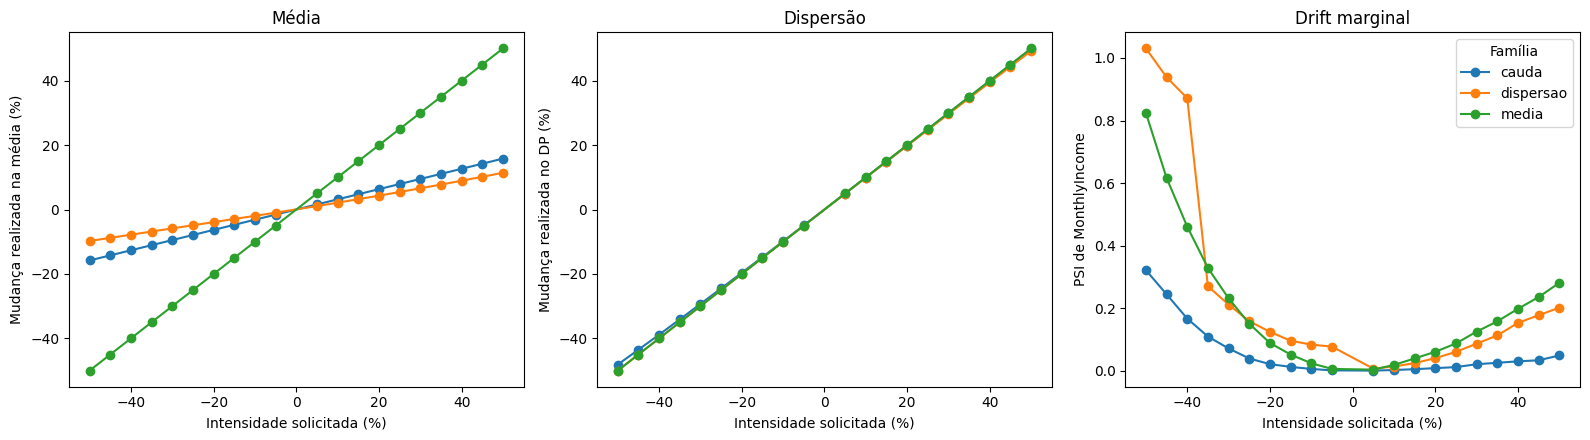

Legenda: “média”, “dispersão” e “cauda” são regras distintas. O PSI pode ser diferente para a mesma intensidade aplicada e não é uma porcentagem.


In [9]:
# A marginal da renda independe de λ; usamos λ=0 para evitar sobreposição de pontos.
base = results[results['propagacao_lambda']==0]
fig, axes = plt.subplots(1,3,figsize=(16,4.5))
for family,d in base.groupby('familia'):
    d=d.sort_values('intensidade_solicitada_pct')
    axes[0].plot(d['intensidade_solicitada_pct'],d['media_realizada_pct'],'o-',label=family)
    axes[1].plot(d['intensidade_solicitada_pct'],d['dp_realizado_pct'],'o-',label=family)
    axes[2].plot(d['intensidade_solicitada_pct'],d['psi_alvo'],'o-',label=family)
axes[0].set(xlabel='Intensidade solicitada (%)',ylabel='Mudança realizada na média (%)',title='Média')
axes[1].set(xlabel='Intensidade solicitada (%)',ylabel='Mudança realizada no DP (%)',title='Dispersão')
axes[2].set(xlabel='Intensidade solicitada (%)',ylabel='PSI de MonthlyIncome',title='Drift marginal')
axes[2].legend(title='Família')
plt.tight_layout();plt.show()
print('Legenda: “média”, “dispersão” e “cauda” são regras distintas. O PSI pode ser diferente para a mesma intensidade aplicada e não é uma porcentagem.')

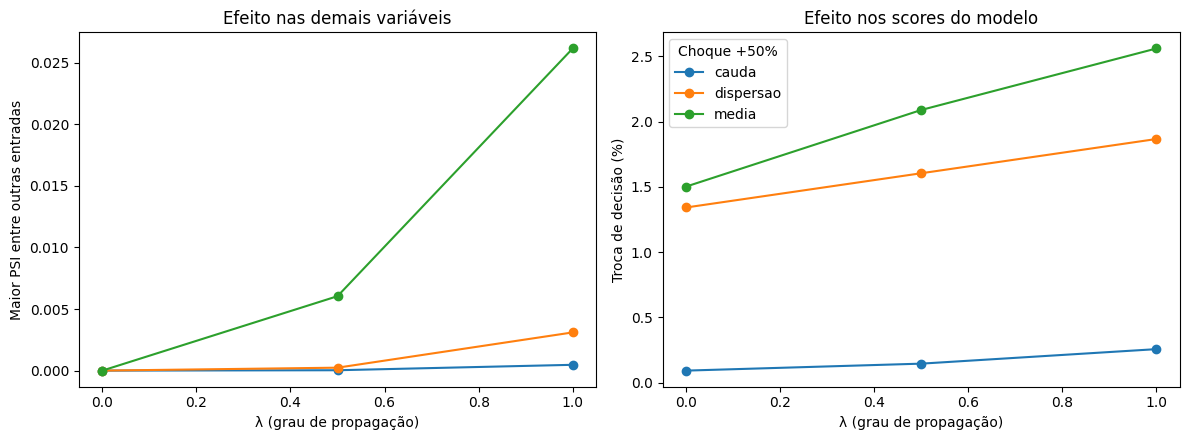

Legenda: para cada família, o choque na renda é idêntico ao variar λ. λ=0 deixa as outras colunas fixas; λ=1 aplica a atualização condicional latente completa.


In [10]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for family,d in results[np.isclose(results['intensidade_solicitada_pct'],50)].groupby('familia'):
    d=d.sort_values('propagacao_lambda')
    axes[0].plot(d['propagacao_lambda'],d['psi_max_outras'],'o-',label=family)
    axes[1].plot(d['propagacao_lambda'],100*d['troca_decisao'],'o-',label=family)
axes[0].set(xlabel='λ (grau de propagação)',ylabel='Maior PSI entre outras entradas',title='Efeito nas demais variáveis')
axes[1].set(xlabel='λ (grau de propagação)',ylabel='Troca de decisão (%)',title='Efeito nos scores do modelo')
axes[1].legend(title='Choque +50%')
plt.tight_layout();plt.show()
print('Legenda: para cada família, o choque na renda é idêntico ao variar λ. λ=0 deixa as outras colunas fixas; λ=1 aplica a atualização condicional latente completa.')

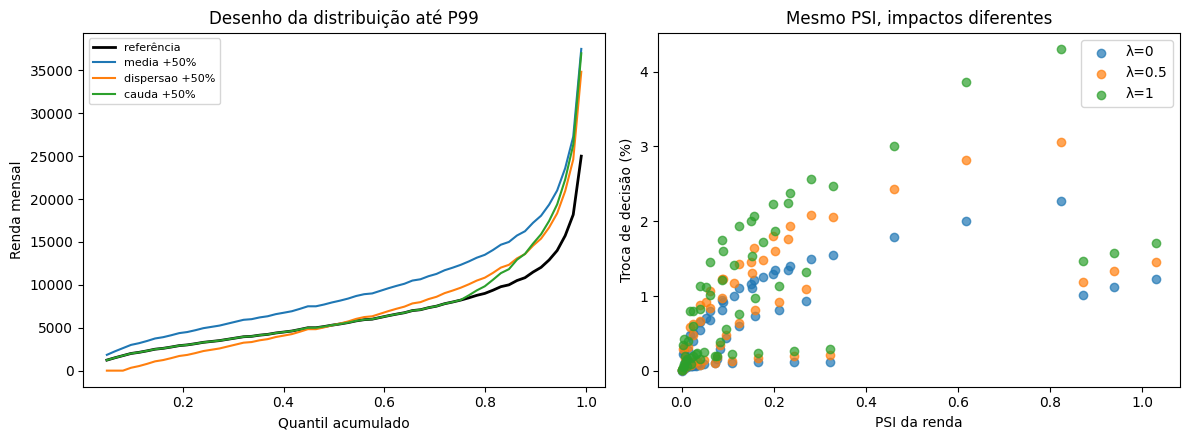

Legenda: à esquerda, cada curva é a função quantil observada em um cenário +50%, com λ=0. À direita, os 180 cenários mostram que PSI da renda sozinho não determina a resposta do modelo.


In [11]:
# Quantis deixam visível a mudança de forma sem ocultar a distribuição pela renda extrema.
qgrid=np.linspace(.05,.99,60)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].plot(qgrid,np.quantile(ref_income,qgrid),color='black',lw=2,label='referência')
for family in ('media','dispersao','cauda'):
    frame,_=simulate(family,.50,0)
    axes[0].plot(qgrid,np.quantile(frame[TARGET].dropna(),qgrid),label=family+' +50%')
axes[0].set(xlabel='Quantil acumulado',ylabel='Renda mensal',title='Desenho da distribuição até P99')
axes[0].legend(fontsize=8)
for propagation in (0,.5,1):
    d=results[results['propagacao_lambda']==propagation]
    axes[1].scatter(d['psi_alvo'],100*d['troca_decisao'],alpha=.7,label=f'λ={propagation:g}')
axes[1].set(xlabel='PSI da renda',ylabel='Troca de decisão (%)',title='Mesmo PSI, impactos diferentes')
axes[1].legend()
plt.tight_layout();plt.show()
print('Legenda: à esquerda, cada curva é a função quantil observada em um cenário +50%, com λ=0. À direita, os 180 cenários mostram que PSI da renda sozinho não determina a resposta do modelo.')

## 7. Validar a dependência e a coerência do cenário

O cenário abaixo usa aumento de 50% pela regra de escala e $\lambda=1$. Comparamos a correlação de Spearman antes e depois, a alteração das outras variáveis e a presença de valores negativos. Uma diferença na matriz não invalida automaticamente o cenário: pode ser efeito esperado da nova composição, dos empates ou da regra condicional. Já um cenário economicamente impossível exige redesenho. Esta checagem automatizada só cobre faixas não negativas e integridade de ausentes; regras completas de crédito exigem conhecimento de negócio.

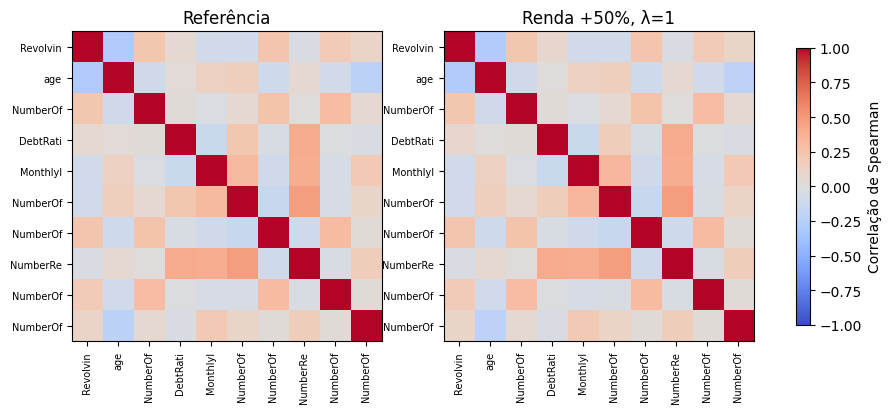

Legenda: as mesmas cores representam correlações de postos comparáveis; abreviações nos eixos seguem a ordem completa das dez features listadas no manifesto.


,variavel,psi,ausentes_base_pct,ausentes_cenario_pct,mediana_base,mediana_cenario
0,RevolvingUtilizationOfUnsecuredLines,0.002,0.000,0.000,0.155,0.141
1,age,0.004,0.000,0.000,52.000,53.000
2,NumberOfTime30-59DaysPastDueNotWorse,0.000,0.000,0.000,0.000,0.000
3,DebtRatio,0.006,0.000,0.000,0.367,0.347
4,MonthlyIncome,0.281,19.689,19.689,5333.000,7999.500
5,NumberOfOpenCreditLinesAndLoans,0.026,0.000,0.000,8.000,8.000
6,NumberOfTimes90DaysLate,0.000,0.000,0.000,0.000,0.000
7,NumberRealEstateLoansOrLines,0.000,0.000,0.000,1.000,1.000
8,NumberOfTime60-89DaysPastDueNotWorse,0.000,0.000,0.000,0.000,0.000
9,NumberOfDependents,0.000,2.720,2.720,0.000,0.000


Valores negativos no cenário: 0


In [12]:
exemplar, dz=simulate('media',.50,1.0)
ex_corr=exemplar[FEATURES].corr(method='spearman')
fig,axes=plt.subplots(1,2,figsize=(11,4.8))
for ax,mat,title in zip(axes,(ref_corr,ex_corr),('Referência','Renda +50%, λ=1')):
    im=ax.imshow(mat,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_title(title)
    ax.set_xticks(range(len(FEATURES)),[f[:8] for f in FEATURES],rotation=90,fontsize=7)
    ax.set_yticks(range(len(FEATURES)),[f[:8] for f in FEATURES],fontsize=7)
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.75,label='Correlação de Spearman')
plt.show()
print('Legenda: as mesmas cores representam correlações de postos comparáveis; abreviações nos eixos seguem a ordem completa das dez features listadas no manifesto.')
diagnostic=pd.DataFrame({
    'variavel':FEATURES,
    'psi':[psi(X_hold[f],exemplar[f]) for f in FEATURES],
    'ausentes_base_pct':[100*X_hold[f].isna().mean() for f in FEATURES],
    'ausentes_cenario_pct':[100*exemplar[f].isna().mean() for f in FEATURES],
    'mediana_base':[X_hold[f].median() for f in FEATURES],
    'mediana_cenario':[exemplar[f].median() for f in FEATURES],
})
display(diagnostic.round(3))
print('Valores negativos no cenário:',sum(int((exemplar[f].dropna()<0).sum()) for f in FEATURES))

## 8. Como interpretar e replicar

1. Escolha uma característica, um mecanismo plausível e uma faixa de intensidades. Uma multiplicação de 50% da renda é uma hipótese **diferente** de aumentar 15% a dispersão ou apenas a cauda. Não interprete o parâmetro como drift observado: leia `media_realizada_pct`, `dp_realizado_pct`, `psi_alvo` e `wasserstein_alvo_por_iqr`.
2. Compare $\lambda=0$ com $0{,}5$ e $1$ **no mesmo choque**. `psi_alvo` é igual, mas `psi_max_outras`, `gap_spearman_medio`, scores e decisões podem divergir. Essa comparação quantifica o efeito da regra de propagação.
3. Antes de interpretar como cenário plausível, verifique se o simulador representa cenários econômicos plausíveis, se `fora_suporte_alvo` é baixo e se dependências, ausentes, zeros, inteiros e combinações de cauda são coerentes. A cópula normal pode falhar em dependência extrema de cauda; não a trate como geradora de um futuro garantido.
4. Para outras bases, substitua o modelo, o split, as features, a variável de choque, limites físicos e regras de integridade. Ajuste e congele a referência em dados próprios de desenvolvimento. Com novas safras rotuladas, avalie separadamente Brier, AUC ROC, PR-AUC trapezoidal e KS do modelo. Recall e precisão em 0,50 podem ser referências, sem funcionar como critério de parada neste experimento.

**Fontes metodológicas:** [Liu et al., *The Nonparanormal*: cópula gaussiana semiparamétrica](https://www.jmlr.org/papers/volume10/liu09a/liu09a.pdf); [Liu et al., estimadores baseados em postos](https://arxiv.org/abs/1202.2169); [SciPy: postos com empates](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.rankdata.html); [SciPy: distribuição normal e quantis](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html); [SciPy: distância de Wasserstein](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html).